# Exploratory Data Analysis: Heart Failure Prediction

Goal: understand the 918-patient dataset before modeling, and find data-quality issues that shape preprocessing.

In [8]:
import sys; sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt
from src.preprocess import load_config, load_data

cfg = load_config('../configs/config.yaml')
df = load_data(cfg['data']['path'])
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [9]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


## Target balance
About 55% of patients have heart disease, so classes are reasonably balanced; accuracy is meaningful but recall matters most for screening.

In [10]:
df['HeartDisease'].value_counts(normalize=True).round(3)

HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64

## Hidden missing values
There are no NaNs, but `Cholesterol = 0` and `RestingBP = 0` are physiologically impossible. They are placeholders for *not recorded*.

In [11]:
(df[['RestingBP', 'Cholesterol', 'MaxHR', 'Age']] == 0).sum()

RestingBP        1
Cholesterol    172
MaxHR            0
Age              0
dtype: int64

Is missingness random? If not, a missing-indicator feature is worth keeping.

In [12]:
df.assign(chol_missing=df['Cholesterol'].eq(0)).groupby('chol_missing')['HeartDisease'].agg(['mean', 'count'])

,mean,count
chol_missing,,
False,0.477212,746
True,0.883721,172


## Numeric features by outcome

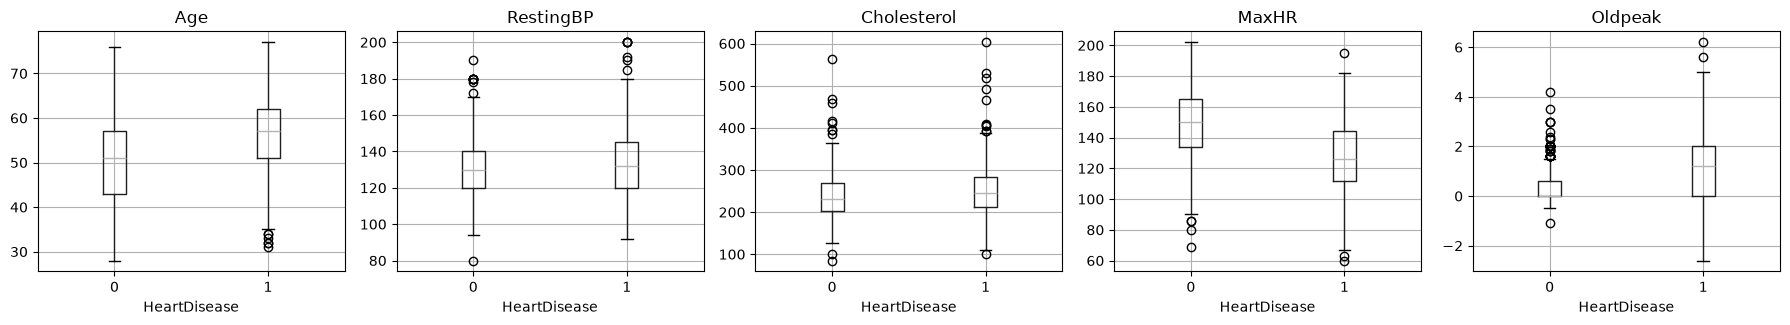

In [13]:
num = cfg['features']['numeric']
fig, axes = plt.subplots(1, len(num), figsize=(18, 3.5))
for ax, col in zip(axes, num):
    data = df[df[col] > 0] if col in cfg['data']['zero_as_missing'] else df
    data.boxplot(column=col, by='HeartDisease', ax=ax)
    ax.set_title(col); ax.set_xlabel('HeartDisease')
plt.suptitle(''); plt.tight_layout()

## Categorical features: disease rate per level

In [14]:
for col in cfg['features']['categorical'] + cfg['features']['binary']:
    print(df.groupby(col)['HeartDisease'].agg(['mean', 'count']).round(2), '\n')

     mean  count
Sex             
F    0.26    193
M    0.63    725 

               mean  count
ChestPainType             
ASY            0.79    496
ATA            0.14    173
NAP            0.35    203
TA             0.43     46 

            mean  count
RestingECG             
LVH         0.56    188
Normal      0.52    552
ST          0.66    178 

                mean  count
ExerciseAngina             
N               0.35    547
Y               0.85    371 

          mean  count
ST_Slope             
Down      0.78     63
Flat      0.83    460
Up        0.20    395 

           mean  count
FastingBS             
0          0.48    704
1          0.79    214 



## Takeaways for preprocessing
- Convert zero placeholders to NaN; impute with the **training** median inside the pipeline (no leakage) and keep a missing-indicator.
- One-hot encode the five categorical features; scale numerics (needed for logistic regression, harmless for trees).
- Stratify the train/test split on the target.

## Key findings
- **Missing cholesterol is not random.** 172 patients (19%) have `Cholesterol = 0`, and 88% of them have heart disease, versus 48% of patients with a recorded value. The missingness is concentrated in particular source cohorts, so it carries signal; this is why the pipeline keeps a missing-indicator feature instead of silently imputing. It also means the model may partly learn *where* a patient was treated, not only their physiology.
- **Asymptomatic chest pain carries the highest risk.** Patients reporting no chest pain (`ASY`, 496 patients) have a 79% disease rate, versus 14% for atypical angina. Many patients with heart disease in these cohorts had no typical symptoms.
- **Exercise-induced angina is a strong signal:** 85% disease rate with it, 35% without.
- **The data is male-heavy.** 79% of patients are men (63% disease rate, versus 26% for women), so predictions for women rest on far fewer examples (193 patients).